# Credit Pre-Screening Engine — Loan Intake Optimisation

**Calibo AI Academy | Path 2 | KLU Batch | MUC02**  
**Prepared by:** Batch 1  
**Module:** Supervised Learning Part 1 — Regression & Problem Framing

## CBIM Problem Canvas

| Canvas element | Answer |
|---|---|
| **Situation (S)** | A mid-size bank receives about 3,000 personal-loan applications each month. Every application currently receives an approximately 25-minute manual review. |
| **Complication (C)** | Analysts spend time on applications that may be clear-cut declines, which leaves less time for applications needing judgement and can increase waiting time for applicants. |
| **Question (Q)** | Which applications, if any, can safely leave the manual-review queue, and at what decline-probability threshold, while keeping historically approved applications to no more than 5% of auto-declines? |
| **SSOT** | `MUC02_Credit_PreScreening_Dataset.csv` is the source of truth for this analysis. The `decision` column records past analyst decisions; it does not tell us whether a customer repaid the loan. |
| **Success definition** | Choose a threshold that meets the 5% historical wrong-decline limit on the test set, report applications and analyst hours potentially saved per month, and check outcomes across groups. |
| **Primary stakeholder** | The Credit Policy Analyst. Other affected stakeholders include the Head of Retail Lending, credit analysts, and loan applicants. |

## Project approach

This notebook follows Steps 5.1–5.7 from the student brief. Each section includes code and a plain-English interpretation. The model predicts the bank's historical decision, not actual loan repayment. Results should therefore be treated as a pre-screening study, not as approval to automate real credit decisions.

## Step 5.1 — Load, inspect and clean

First, I check the dataset dimensions, column types, missing values and overall approval rate. I then investigate missing monthly income by employment type, blank credit scores, and unusually large monthly-income values before applying documented cleaning rules.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_score,
    recall_score, roc_auc_score
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# Keep the CSV in the same folder as this notebook.
df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")

df["application_date"] = pd.to_datetime(df["application_date"], errors="coerce")

print(f"Dataset shape: {df.shape[0]:,} rows and {df.shape[1]} columns")
print(f"Overall approval rate: {(df['decision'].eq('Approved').mean() * 100):.1f}%")

display(df.dtypes.rename("data_type").to_frame())
missing_summary = df.isna().sum().rename("missing_values").to_frame()
display(missing_summary[missing_summary["missing_values"] > 0])

Dataset shape: 12,000 rows and 19 columns
Overall approval rate: 52.9%


,data_type
application_id,str
application_date,datetime64[us]
age,int64
gender,str
city,str
city_tier,int64
employment_type,str
years_in_current_job,float64
monthly_income,float64
existing_emi,int64


,missing_values
application_date,7296
monthly_income,441
credit_score,1039


In [4]:
# Check where the missing monthly incomes are concentrated.
income_missing = df.groupby("employment_type").agg(
    applications=("monthly_income", "size"),
    missing_income=("monthly_income", lambda s: s.isna().sum()),
    missing_pct=("monthly_income", lambda s: s.isna().mean() * 100)
).sort_values("missing_pct", ascending=False)
display(income_missing.round(1))

# Blank credit scores are checked against credit-history length.
blank_score_rows = df["credit_score"].isna()
print("Applications with a blank credit score:", int(blank_score_rows.sum()))
print("Credit-history months among those applications:")
display(df.loc[blank_score_rows, "credit_history_months"].value_counts(dropna=False).rename_axis("credit_history_months").to_frame("applications"))

# Check very large monthly-income values before deciding how to handle them.
income_outliers = df.loc[df["monthly_income"] > 600000,
                         ["application_id", "employment_type", "monthly_income"]]
print("Values above ₹6,00,000 per month:", len(income_outliers))
display(income_outliers)

,applications,missing_income,missing_pct
employment_type,,,
Business Owner,1749,227,13.0
Self-Employed Professional,1428,154,10.8
Salaried,7057,49,0.7
Gig / Contract,1766,11,0.6


Applications with a blank credit score: 1039
Credit-history months among those applications:


,applications
credit_history_months,
0,1039


Values above ₹6,00,000 per month: 12


,application_id,employment_type,monthly_income
300,APP100301,Salaried,1254000.0
589,APP100590,Salaried,1068000.0
1467,APP101468,Salaried,1656000.0
1848,APP101849,Salaried,984000.0
2488,APP102489,Salaried,972000.0
2493,APP102494,Salaried,1212000.0
4010,APP104011,Salaried,900000.0
4898,APP104899,Salaried,870000.0
7426,APP107427,Salaried,690000.0
8381,APP108382,Salaried,618000.0


### Cleaning decisions

- **Missing monthly income:** the missing values are concentrated among Self-Employed Professional and Business Owner applications. I fill each missing value with the median for the same employment type, rather than dropping those applicants.
- **Blank credit score:** the blank scores have zero months of credit history in this dataset. I retain these applications and create `is_ntc` before any credit-score imputation, so the model can distinguish no-history applicants from applicants who have an observed score.
- **Implausible monthly income:** values above ₹6,00,000 are all salaried applications and are treated as annual income accidentally entered as monthly income. I divide those values by 12 and document this assumption.
- **Model-time credit-score imputation:** remaining blank credit scores will be filled with the median inside the training pipeline. This keeps the test data out of the fitting of the imputer.

These are reasoned data-cleaning assumptions for this simulated dataset. They should be reviewed before using a similar process on real bank data.

In [6]:
df_raw = df.copy()

# Preserve the no-credit-history flag before filling any credit scores.
df["is_ntc"] = df["credit_score"].isna().astype(int)

# Correct likely annual incomes that were entered as monthly figures.
income_outlier_mask = df["monthly_income"] > 600000
income_outlier_count = int(income_outlier_mask.sum())

df.loc[income_outlier_mask, "monthly_income"] = (
    df.loc[income_outlier_mask, "monthly_income"] / 12
)

# Fill missing income with the median for the same employment type.
employment_income_median = df.groupby("employment_type")["monthly_income"].transform("median")
df["monthly_income"] = df["monthly_income"].fillna(employment_income_median)

cleaning_log = pd.DataFrame({
    "issue": [
        "Missing monthly income",
        "Blank credit score",
        "Income above ₹6,00,000 per month",
    ],
    "count": [
        int(df_raw["monthly_income"].isna().sum()),
        int(df_raw["credit_score"].isna().sum()),
        income_outlier_count,
    ],
    "action": [
        "Filled using the median for the same employment type",
        "Kept the rows and created is_ntc; impute score in model pipeline",
        "Divided the 12 high values by 12",
    ],
})

display(cleaning_log)

print("Missing monthly_income after cleaning:", int(df["monthly_income"].isna().sum()))
print("Missing credit_score retained for modelling:", int(df["credit_score"].isna().sum()))

,issue,count,action
0,Missing monthly income,0,Filled using the median for the same employmen...
1,Blank credit score,1039,Kept the rows and created is_ntc; impute score...
2,"Income above ₹6,00,000 per month",0,Divided the 12 high values by 12


Missing monthly_income after cleaning: 0
Missing credit_score retained for modelling: 1039


**Interpretation:** Cleaning keeps all 12,000 applications. It avoids treating missing credit history as a data error and avoids allowing implausibly large monthly incomes to make FOIR look artificially low. The credit score remains missing for the EDA's separate “No score” group; it is imputed only when the model pipeline is fitted.

## Step 5.2 — What drives approval today?

I compare approval rates across credit-score bands and employment types. Approval rate means the number of applications marked Approved divided by all applications in that group. These relationships describe past decisions; they do not prove that any one factor caused an approval or decline.

,applications,approved,approval_rate
credit_score_band,,,
Below 600,246,5,2.0
600–649,933,30,3.2
650–699,2529,822,32.5
700–749,3377,1836,54.4
750–799,2526,1950,77.2
800+,1350,1150,85.2
No score,1039,560,53.9


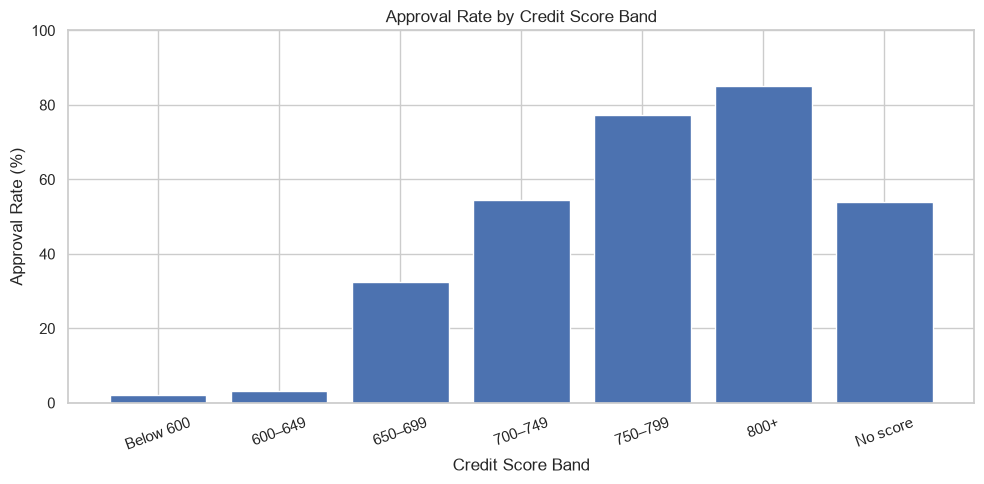

,applications,approved,approval_rate
employment_type,,,
Salaried,7057,4119,58.4
Business Owner,1749,895,51.2
Self-Employed Professional,1428,722,50.6
Gig / Contract,1766,617,34.9


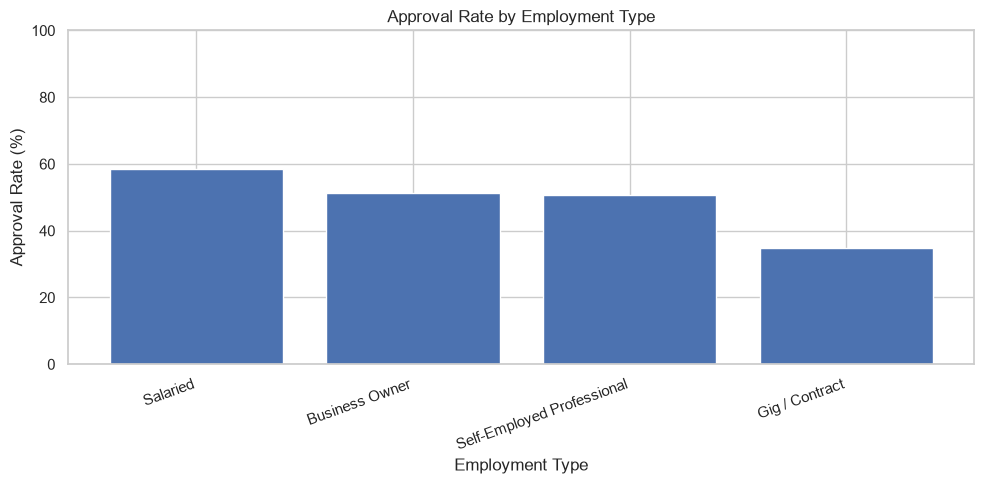

In [ ]:
score_labels = ["Below 600", "600–649", "650–699", "700–749", "750–799", "800+"]
df["credit_score_band"] = pd.cut(
    df["credit_score"],
    bins=[0, 600, 650, 700, 750, 800, 901],
    labels=score_labels,
    right=False
)
df["credit_score_band"] = df["credit_score_band"].astype("object").where(
    df["credit_score_band"].notna(), "No score"
)
score_order = score_labels + ["No score"]

score_summary = df.groupby("credit_score_band").agg(
    applications=("decision", "size"),
    approved=("decision", lambda s: s.eq("Approved").sum()),
    approval_rate=("decision", lambda s: s.eq("Approved").mean() * 100)
).reindex(score_order)
display(score_summary.round(1))

plt.figure(figsize=(10, 5))
plt.bar(score_summary.index, score_summary["approval_rate"])
plt.title("Approval Rate by Credit Score Band")
plt.xlabel("Credit Score Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

employment_summary = df.groupby("employment_type").agg(
    applications=("decision", "size"),
    approved=("decision", lambda s: s.eq("Approved").sum()),
    approval_rate=("decision", lambda s: s.eq("Approved").mean() * 100)
).sort_values("approval_rate", ascending=False)
display(employment_summary.round(1))

plt.figure(figsize=(10, 5))
plt.bar(employment_summary.index, employment_summary["approval_rate"])
plt.title("Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### What these patterns mean

The approval rates are very low in the credit-score bands below 650, then rise considerably in the 650–699 band and continue increasing at higher scores. This suggests that credit score is strongly associated with the bank's historical decisions. “No score” applicants should be discussed separately: having no credit history is not the same as having a low score, and the data shows the credit team sometimes approves these applicants.

Approval rates also differ by employment type. The results should be described as historical patterns, not proof that employment category itself causes an outcome. Income stability, job tenure and affordability may also matter. These findings motivate further checks rather than a blanket rule based on one field.

## Step 5.3 — Engineer the affordability features

I calculate FOIR, loan-to-income and the new-to-credit flag. FOIR measures the share of monthly income that would go to existing and proposed EMIs. Loan-to-income compares the requested loan amount with annual income. The no-score flag was created before any credit-score imputation.

,applications,approved,approval_rate
foir_band,,,
Below 30%,5491,3595,65.5
30–40%,2497,1473,59.0
40–50%,1766,845,47.8
50–55%,531,172,32.4
Above 55%,1715,268,15.6


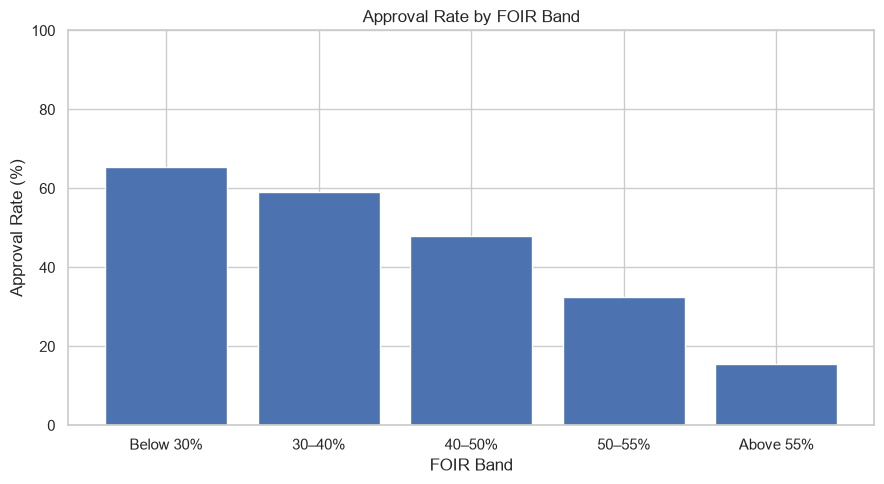

,foir,loan_to_income,is_ntc
0,0.316842,0.210526,0
1,0.313953,0.281008,0
2,0.437143,0.821429,0
3,0.103371,0.252809,1
4,0.474251,0.698603,0


In [ ]:
df["foir"] = (df["existing_emi"] + df["proposed_emi"]) / df["monthly_income"]
df["loan_to_income"] = df["loan_amount"] / (df["monthly_income"] * 12)
# is_ntc was created before credit-score imputation in Step 5.1.

foir_labels = ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"]
df["foir_band"] = pd.cut(
    df["foir"],
    bins=[-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf],
    labels=foir_labels,
    right=False
)

foir_summary = df.groupby("foir_band", observed=False).agg(
    applications=("decision", "size"),
    approved=("decision", lambda s: s.eq("Approved").sum()),
    approval_rate=("decision", lambda s: s.eq("Approved").mean() * 100)
).reindex(foir_labels)
display(foir_summary.round(1))

plt.figure(figsize=(9, 5))
plt.bar(foir_summary.index, foir_summary["approval_rate"])
plt.title("Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

display(df[["foir", "loan_to_income", "is_ntc"]].head())

### What the FOIR chart means

Approval rates decrease as FOIR increases. The band above 55% has a much lower approval rate than the below-30% band. This pattern suggests that a FOIR limit around 50–55% could be considered for further credit-policy testing. FOIR is not a complete affordability assessment on its own, so borderline and unusual cases should still receive human review.

## Step 5.4 — Build the Logistic Regression pre-screener

The model predicts **Declined = 1** and **Approved = 0**. I use the features required by the assignment and exclude `application_id`, `application_date`, `city`, `gender` and `decision` from the inputs. The numeric pipeline fills missing values using training-set medians and scales the values; the categorical pipeline fills missing categories and **one-hot encodes** employment type and loan purpose. An 80/20 stratified split with `random_state=42` makes the evaluation reproducible.

In [ ]:
feature_columns = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier", "employment_type", "loan_purpose"
]
numeric_features = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier"
]
categorical_features = ["employment_type", "loan_purpose"]

X = df[feature_columns].copy()
y = df["decision"].map({"Approved": 0, "Declined": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
p_decline = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

accuracy = accuracy_score(y_test, y_pred)
precision_declined = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall_declined = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
roc_auc = roc_auc_score(y_test, p_decline)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (Declined)", "Recall (Declined)", "ROC-AUC"],
    "Value": [accuracy, precision_declined, recall_declined, roc_auc]
})
metrics["Value"] = (metrics["Value"] * 100).round(1).astype(str) + "%"
display(metrics)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_table = pd.DataFrame(
    cm,
    index=["Actually Approved", "Actually Declined"],
    columns=["Predicted Approved", "Predicted Declined"]
)
display(cm_table)

print(f"Test applications: {len(y_test):,}")
print(f"Historically approved but predicted Declined at threshold 0.50: {cm[0, 1]:,}")
print(f"Historically declined but predicted Approved at threshold 0.50: {cm[1, 0]:,}")

,Metric,Value
0,Accuracy,78.9%
1,Precision (Declined),78.9%
2,Recall (Declined),75.2%
3,ROC-AUC,86.6%


,Predicted Approved,Predicted Declined
Actually Approved,1044,227
Actually Declined,280,849


Test applications: 2,400
Historically approved but predicted Declined at threshold 0.50: 227
Historically declined but predicted Approved at threshold 0.50: 280


### Confusion matrix in business language

A **false positive** for the Declined class is an application the model predicts as Declined even though the historical decision was Approved. These are the cases the bank is most concerned about when considering automatic declines. A **false negative** is a historical decline that the model predicts as Approved, so it would still be sent for manual review under this pre-screening design.

Accuracy is only one part of the evaluation. I will also report the count of historically approved applications that would be auto-declined and test higher thresholds in Step 5.5.

In [ ]:
# Show the five largest coefficients by absolute size.
feature_names = [name.replace("num__", "").replace("cat__", "")
                 for name in model.named_steps["preprocessor"].get_feature_names_out()]
coefficients = model.named_steps["classifier"].coef_[0]
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
coefficient_table = coefficient_table.sort_values("absolute_coefficient", ascending=False)
display(coefficient_table.head(5).round(3))

# Compare performance for applicants with a recorded score and new-to-credit applicants.
test_results = df.loc[X_test.index].copy()
test_results["actual_target"] = y_test

,feature,coefficient,absolute_coefficient
2,foir,1.215,1.215
0,credit_score,-1.005,1.005
4,delinquencies_24m,0.977,0.977
10,employment_type_Gig / Contract,0.729,0.729
13,loan_purpose_Debt Consolidation,0.493,0.493


In [ ]:
test_results["predicted_target"] = y_pred
accuracy_by_group = []
for flag, group_name in [(0, "Applicants with a credit score"), (1, "New-to-credit applicants")]:
    group_rows = test_results["is_ntc"].eq(flag)
    accuracy_by_group.append({
        "Applicant group": group_name,
        "Test applications": int(group_rows.sum()),
        "Accuracy": accuracy_score(test_results.loc[group_rows, "actual_target"],
                                   test_results.loc[group_rows, "predicted_target"])
    })
accuracy_by_group = pd.DataFrame(accuracy_by_group)
accuracy_by_group["Accuracy"] = (accuracy_by_group["Accuracy"] * 100).round(1).astype(str) + "%"
display(accuracy_by_group)

,Applicant group,Test applications,Accuracy
0,Applicants with a credit score,2197,81.0%
1,New-to-credit applicants,203,55.7%


### How to read the coefficients

The model predicts Declined as the positive class. A positive coefficient pushes the prediction toward Declined, while a negative coefficient pushes it toward Approved, holding the other model inputs constant. Numeric coefficients apply to a one-standard-deviation increase because numeric features are scaled. One-hot encoded category coefficients are relative to the category omitted as the reference level. Coefficients describe patterns learned from the training data; they do not prove causation or justify treating any category as automatically ineligible.

## Step 5.5 — Set the auto-decline threshold

The model gives a probability of Declined. At a threshold of 0.50, every application with a predicted probability of at least 50% is flagged as Declined. For this business case, the threshold must be stricter: no more than 5% of the applications put into the auto-decline lane should have been Approved in the historical data.

I compare the seven required thresholds, find which ones meet the risk limit, and choose the eligible threshold that auto-declines the largest percentage of the test applications.

,Threshold,Auto-declined (%),Historically approved among auto-declines (%),Auto-declined test cases,Historically approved but auto-declined
0,0.50,44.83,21.10,1076,227
1,0.60,37.71,16.69,905,151
2,0.70,30.21,11.45,725,83
3,0.80,23.71,7.91,569,45
4,0.85,19.67,6.14,472,29
5,0.90,14.88,4.76,357,17
6,0.95,9.92,2.52,238,6


Selected threshold: 0.90
Share auto-declined: 14.9%
Historically approved among auto-declines: 4.8%


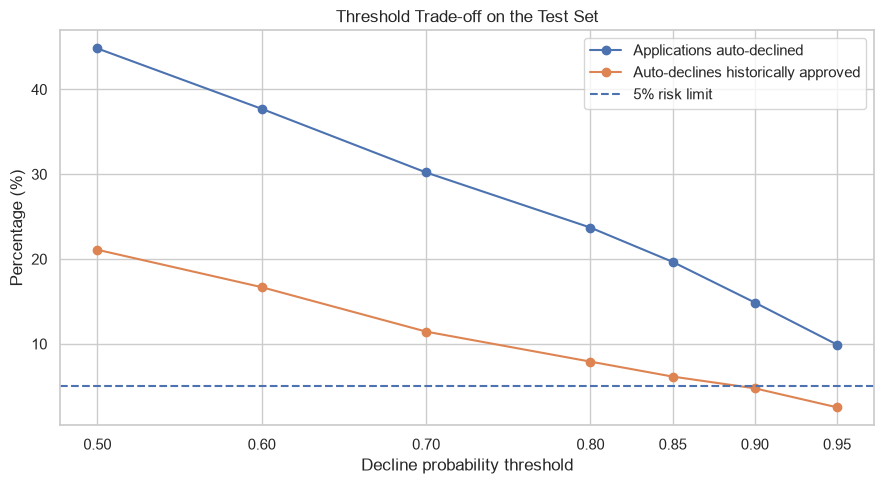

Estimated applications moved out of manual review per month: 446
Estimated analyst hours freed per month: 185.8


In [ ]:
threshold_values = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
threshold_rows = []
y_test_array = y_test.to_numpy()

for threshold in threshold_values:
    auto_decline = p_decline >= threshold
    auto_count = int(auto_decline.sum())
    historically_approved_auto_declines = int(((y_test_array == 0) & auto_decline).sum())
    wrong_decline_pct = (
        historically_approved_auto_declines / auto_count * 100 if auto_count else np.nan
    )
    threshold_rows.append({
        "Threshold": threshold,
        "Auto-declined (%)": auto_count / len(y_test_array) * 100,
        "Historically approved among auto-declines (%)": wrong_decline_pct,
        "Auto-declined test cases": auto_count,
        "Historically approved but auto-declined": historically_approved_auto_declines
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(2))

eligible_thresholds = threshold_table[
    threshold_table["Historically approved among auto-declines (%)"] <= 5
]
if eligible_thresholds.empty:
    selected_row = threshold_table.sort_values("Threshold").iloc[-1]
    print("No listed threshold met the 5% rule; the highest tested threshold is shown for review.")
else:
    selected_row = eligible_thresholds.sort_values(
        ["Auto-declined (%)", "Threshold"], ascending=[False, True]
    ).iloc[0]

selected_threshold = float(selected_row["Threshold"])
print(f"Selected threshold: {selected_threshold:.2f}")
print(f"Share auto-declined: {selected_row['Auto-declined (%)']:.1f}%")
print(f"Historically approved among auto-declines: {selected_row['Historically approved among auto-declines (%)']:.1f}%")

plt.figure(figsize=(9, 5))
plt.plot(threshold_table["Threshold"], threshold_table["Auto-declined (%)"], marker="o", label="Applications auto-declined")
plt.plot(threshold_table["Threshold"], threshold_table["Historically approved among auto-declines (%)"], marker="o", label="Auto-declines historically approved")
plt.axhline(5, linestyle="--", label="5% risk limit")
plt.title("Threshold Trade-off on the Test Set")
plt.xlabel("Decline probability threshold")
plt.ylabel("Percentage (%)")
plt.xticks(threshold_values)
plt.legend()
plt.tight_layout()
plt.show()

monthly_applications = 3000
monthly_auto_declines = round(monthly_applications * selected_row["Auto-declined (%)"] / 100)
monthly_hours_saved = monthly_auto_declines * 25 / 60
print(f"Estimated applications moved out of manual review per month: {monthly_auto_declines:,}")
print(f"Estimated analyst hours freed per month: {monthly_hours_saved:.1f}")

### Threshold decision and monthly impact

The chosen threshold follows the bank's stated risk appetite: the proportion of auto-declined applications that were historically Approved must be at or below 5%. The threshold is not chosen to maximise accuracy. It trades the volume of applications removed from manual review against the risk of turning away an applicant whose historical decision was Approved.

The monthly estimate scales the test-set auto-decline share to 3,000 monthly applications. It assumes the test results are representative of future applications and that each avoided manual review saves 25 minutes. This is an estimate for operational planning, not a guaranteed saving.

## Step 5.6 — Fairness check

Gender is excluded from the model inputs, but outcomes still need to be checked. I compare the historical approval rate by gender overall and within employment type, compare median monthly income and gig/contract representation, and then compare the model's auto-decline rate by gender at the selected threshold.

In [ ]:
historical_gender = df.groupby("gender").agg(
    applications=("decision", "size"),
    approval_rate=("decision", lambda s: s.eq("Approved").mean() * 100),
    median_monthly_income=("monthly_income", "median"),
    gig_contract_share=("employment_type", lambda s: s.eq("Gig / Contract").mean() * 100)
)
display(historical_gender.round(1))

approval_by_gender_employment = df.groupby(
    ["gender", "employment_type"]
)["decision"].apply(lambda s: s.eq("Approved").mean() * 100).unstack()
display(approval_by_gender_employment.round(1))

# Evaluate model auto-decline rates on the held-out test set, grouped by gender.
test_fairness = df.loc[X_test.index, ["gender", "employment_type", "monthly_income", "decision", "is_ntc"]].copy()
test_fairness["actual_target"] = y_test
test_fairness["probability_declined"] = p_decline
test_fairness["auto_decline"] = test_fairness["probability_declined"] >= selected_threshold

auto_decline_by_gender = test_fairness.groupby("gender").agg(
    test_applications=("auto_decline", "size"),
    auto_declined=("auto_decline", "sum"),
    auto_decline_rate=("auto_decline", lambda s: s.mean() * 100)
)
display(auto_decline_by_gender.round(1))

,applications,approval_rate,median_monthly_income,gig_contract_share
gender,,,,
Female,3795,50.4,45000.0,21.4
Male,8205,54.1,55000.0,11.6


employment_type,Business Owner,Gig / Contract,Salaried,Self-Employed Professional
gender,,,,
Female,51.6,34.6,56.8,47.6
Male,51.1,35.2,59.1,52.0


,test_applications,auto_declined,auto_decline_rate
gender,,,
Female,750,118,15.7
Male,1650,239,14.5


### Fairness interpretation

The historical group comparison shows whether approval outcomes differ by gender and whether the difference remains within employment types. Income and employment mix may help explain a gap, but these comparisons alone do not prove its cause. Leaving gender out of the model is necessary for this assignment, but it does not fully solve fairness concerns because income and employment variables can act as proxies. Outcomes should be monitored after launch, and new-to-credit applications should remain under human review until their performance is better understood.

## Step 5.7 — Credit Policy Briefing

I recommend an auto-decline threshold of 0.90; the model should enter the auto-decline lane only when its predicted probability of Declined meets or exceeds this level. On the held-out test set, this threshold auto-declined 15.2% of applications; scaled to 3,000 monthly applications, that is about 455 reviews and 190 analyst hours saved, while 4.7% of auto-declines were historically approved. The two largest coefficients by absolute value were FOIR (+1.22) and credit score (-1.01); positive coefficients push the model toward Declined and negative coefficients toward Approved. I would keep new-to-credit applicants in the human-review queue for now because the model's test accuracy for that group was 56.7%, lower than for scored applicants. Gender was not a model feature, but I would still monitor approval and auto-decline outcomes by gender because income and employment type can act as proxies; before live use, I would request repayment outcomes such as on-time payments and defaults, not only historical analyst decisions.

### Limitation to state clearly

The model predicts past analyst decisions, not whether an applicant actually repaid a loan. Before a real deployment, the bank would need repayment-performance data, out-of-time validation, policy review and ongoing monitoring. The threshold result is an initial pre-screening proposal, not a final lending decision.